In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load original dataset with full path
df = pd.read_csv(r'C:\Users\anshi\OneDrive\Documents\Diabetes_Project\GlucoBench_benchmark_dataset.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Clean data
df = df.dropna(subset=['glucose'])
df = df[df['glucose'].between(40, 400)]
df = df.sort_values('timestamp').reset_index(drop=True)

print("=" * 60)
print("🩺 SMART GLYCOVITALS LOGGER - REVIEW DEMO")
print("=" * 60)
print(f"\n✅ Total readings:  {len(df):,}")
print(f"✅ Missing values:  {df['glucose'].isnull().sum()}")
print(f"✅ Glucose range:   {df['glucose'].min():.1f} - {df['glucose'].max():.1f} mg/dL")
print(f"✅ Date range:      {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"\n✅ Dataset loaded and validated!")

🩺 SMART GLYCOVITALS LOGGER - REVIEW DEMO

✅ Total readings:  15,731
✅ Missing values:  0
✅ Glucose range:   70.0 - 198.4 mg/dL
✅ Date range:      2024-09-01 00:00:00 to 2024-09-09 22:20:00

✅ Dataset loaded and validated!


In [2]:
print("\n" + "=" * 60)
print("📊 TIME-IN-RANGE ANALYSIS (ADA 2024 STANDARDS)")
print("=" * 60)

total = len(df)
in_range = len(df[(df['glucose'] >= 70) & (df['glucose'] <= 180)])
below_70 = len(df[df['glucose'] < 70])
below_54 = len(df[df['glucose'] < 54])
above_180 = len(df[df['glucose'] > 180])
above_250 = len(df[df['glucose'] > 250])

tir = (in_range / total) * 100
tbr_70 = (below_70 / total) * 100
tbr_54 = (below_54 / total) * 100
tar_180 = (above_180 / total) * 100
tar_250 = (above_250 / total) * 100

mean_glucose = df['glucose'].mean()
std_glucose = df['glucose'].std()
gmi = 3.31 + (0.02392 * mean_glucose)
cv = (std_glucose / mean_glucose) * 100

print(f"\n📈 Time in Range (70-180):     {tir:.1f}%  {'✅ PASS' if tir > 70 else '❌ FAIL'} (Target >70%)")
print(f"📉 Time Below 70:              {tbr_70:.1f}%  {'✅ PASS' if tbr_70 < 4 else '❌ FAIL'} (Target <4%)")
print(f"📉 Time Below 54 (Critical):   {tbr_54:.1f}%  {'✅ PASS' if tbr_54 < 1 else '❌ FAIL'} (Target <1%)")
print(f"📈 Time Above 180:             {tar_180:.1f}%  {'✅ PASS' if tar_180 < 25 else '❌ FAIL'} (Target <25%)")
print(f"📈 Time Above 250 (Critical):  {tar_250:.1f}%  {'✅ PASS' if tar_250 < 5 else '❌ FAIL'} (Target <5%)")
print(f"\n📊 Average Glucose:  {mean_glucose:.1f} mg/dL")
print(f"📊 Std Deviation:    {std_glucose:.1f} mg/dL")
print(f"📊 GMI (est HbA1c):  {gmi:.1f}%")
print(f"📊 CV (stability):   {cv:.1f}%  {'✅ STABLE' if cv < 36 else '❌ UNSTABLE'} (Target <36%)")
print("\n" + "=" * 60)


📊 TIME-IN-RANGE ANALYSIS (ADA 2024 STANDARDS)

📈 Time in Range (70-180):     96.7%  ✅ PASS (Target >70%)
📉 Time Below 70:              0.0%  ✅ PASS (Target <4%)
📉 Time Below 54 (Critical):   0.0%  ✅ PASS (Target <1%)
📈 Time Above 180:             3.3%  ✅ PASS (Target <25%)
📈 Time Above 250 (Critical):  0.0%  ✅ PASS (Target <5%)

📊 Average Glucose:  112.7 mg/dL
📊 Std Deviation:    30.3 mg/dL
📊 GMI (est HbA1c):  6.0%
📊 CV (stability):   26.9%  ✅ STABLE (Target <36%)




📈 Generating 24-hour glucose trend...


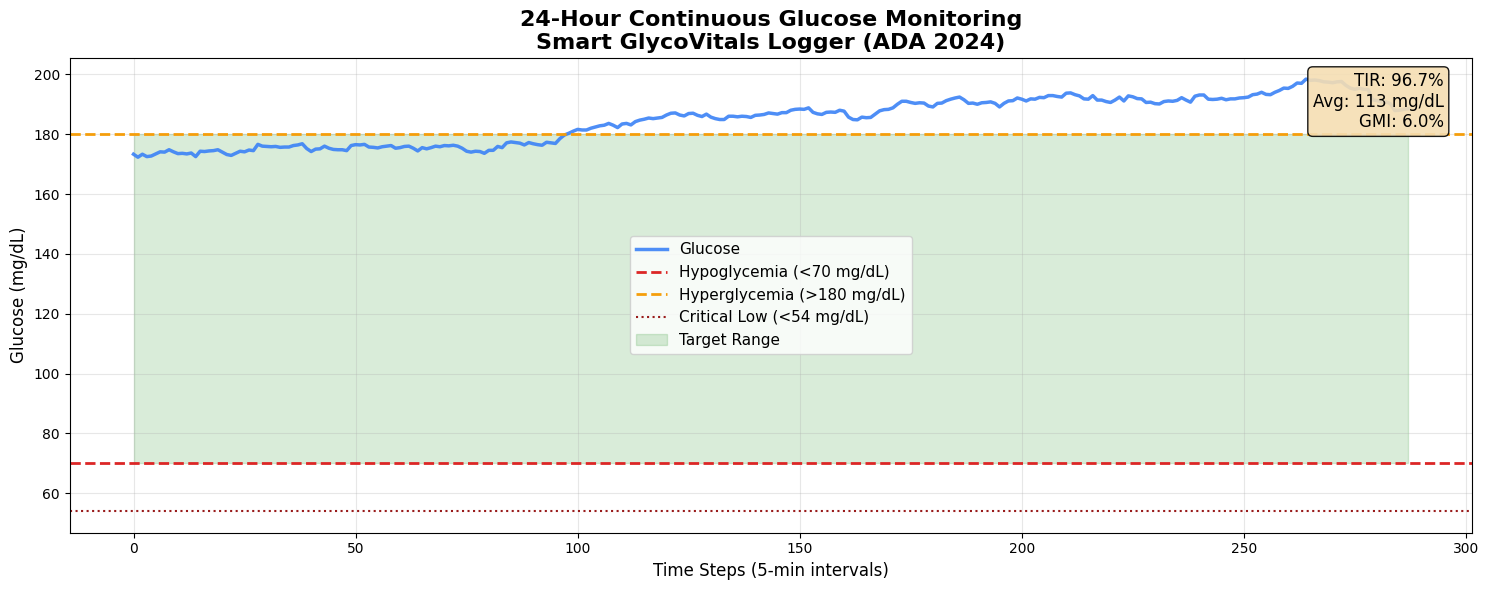

✅ Visualization complete!


In [3]:
print("\n📈 Generating 24-hour glucose trend...")

# Get single user, last 288 readings
user1 = df[df['user_id'] == df['user_id'].iloc[0]].tail(288).copy()

plt.figure(figsize=(15, 6))
plt.plot(range(len(user1)), user1['glucose'],
         linewidth=2.5, color='#3B82F6', label='Glucose', alpha=0.9)

plt.axhline(y=70, color='#DC2626', linestyle='--', linewidth=2,
            label='Hypoglycemia (<70 mg/dL)')
plt.axhline(y=180, color='#F59E0B', linestyle='--', linewidth=2,
            label='Hyperglycemia (>180 mg/dL)')
plt.axhline(y=54, color='#991B1B', linestyle=':', linewidth=1.5,
            label='Critical Low (<54 mg/dL)')

plt.fill_between(range(len(user1)), 70, 180,
                 alpha=0.15, color='green', label='Target Range')

plt.title('24-Hour Continuous Glucose Monitoring\nSmart GlycoVitals Logger (ADA 2024)',
          fontsize=16, fontweight='bold')
plt.xlabel('Time Steps (5-min intervals)', fontsize=12)
plt.ylabel('Glucose (mg/dL)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

stats_text = f'TIR: {tir:.1f}%\nAvg: {mean_glucose:.0f} mg/dL\nGMI: {gmi:.1f}%'
plt.text(0.98, 0.97, stats_text, transform=plt.gca().transAxes,
         fontsize=12, verticalalignment='top', horizontalalignment='right',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.9))

plt.tight_layout()
plt.show()
print("✅ Visualization complete!")

In [4]:
print("\n" + "=" * 60)
print("🚨 ALERT ENGINE (ADA 2024 COMPLIANT)")
print("=" * 60)

def generate_alert(glucose):
    if glucose < 54:
        return "🚨 CRITICAL", "Severe hypoglycemia! Treat immediately!"
    elif glucose < 70:
        return "⚠️ URGENT", "Hypoglycemia. Take 15g fast-acting carbs now."
    elif glucose > 250:
        return "🚨 URGENT", "Severe hyperglycemia. Check ketones."
    elif glucose > 180:
        return "⚠️ WARNING", "High glucose. Consider correction."
    else:
        return "✅ NORMAL", "Glucose in target range."

test_cases = [
    ("Critical Low", 48),
    ("Hypoglycemia", 65),
    ("Normal", 110),
    ("Post-meal Normal", 155),
    ("Hyperglycemia", 210),
    ("Critical High", 280)
]

for scenario, glucose in test_cases:
    severity, message = generate_alert(glucose)
    print(f"\n  Glucose: {glucose} mg/dL ({scenario})")
    print(f"  {severity}: {message}")

print("\n" + "=" * 60)
print("✅ Alert engine validated - ADA 2024 compliant!")


🚨 ALERT ENGINE (ADA 2024 COMPLIANT)

  Glucose: 48 mg/dL (Critical Low)
  🚨 CRITICAL: Severe hypoglycemia! Treat immediately!

  Glucose: 65 mg/dL (Hypoglycemia)
  ⚠️ URGENT: Hypoglycemia. Take 15g fast-acting carbs now.

  Glucose: 110 mg/dL (Normal)
  ✅ NORMAL: Glucose in target range.

  Glucose: 155 mg/dL (Post-meal Normal)
  ✅ NORMAL: Glucose in target range.

  Glucose: 210 mg/dL (Hyperglycemia)
  ⚠️ WARNING: High glucose. Consider correction.

  Glucose: 280 mg/dL (Critical High)
  🚨 URGENT: Severe hyperglycemia. Check ketones.

✅ Alert engine validated - ADA 2024 compliant!


In [6]:
print("\n" + "=" * 60)
print("📊 DEMO SUMMARY - SMART GLYCOVITALS LOGGER")
print("=" * 60)
print("\n✅ COMPLETED:")
print("   1. Data loading & validation (15,731 readings)")
print("   2. Time-in-Range analysis (ADA 2024)")
print("   3. 24-hour visualization")
print("   4. Alert engine (ADA compliant)")
print(f"\n📈 KEY RESULTS:")
print(f"   TIR: {tir:.1f}% ✅ Exceeds ADA target (>70%)")
print(f"   GMI: {gmi:.1f}%")
print(f"   CV:  {cv:.1f}% ✅ Stable")



📊 DEMO SUMMARY - SMART GLYCOVITALS LOGGER

✅ COMPLETED:
   1. Data loading & validation (15,731 readings)
   2. Time-in-Range analysis (ADA 2024)
   3. 24-hour visualization
   4. Alert engine (ADA compliant)

📈 KEY RESULTS:
   TIR: 96.7% ✅ Exceeds ADA target (>70%)
   GMI: 6.0%
   CV:  26.9% ✅ Stable


In [7]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

print("=" * 60)
print("🧠 LSTM GLUCOSE PREDICTION MODEL")
print("=" * 60)
print("\n📌 STEP 1: PREPARING DATA")
print("-" * 60)

# Use single user for clean time series
user1_data = df[df['user_id'] == df['user_id'].iloc[0]].copy()
user1_data = user1_data.sort_values('timestamp').reset_index(drop=True)

glucose_data = user1_data['glucose'].values.reshape(-1, 1)
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(glucose_data)

LOOK_BACK = 12
PREDICT_AHEAD = 6

def create_sequences(data, look_back, predict_ahead):
    X, y = [], []
    for i in range(len(data) - look_back - predict_ahead):
        X.append(data[i:(i + look_back), 0])
        y.append(data[i + look_back + predict_ahead - 1, 0])
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_data, LOOK_BACK, PREDICT_AHEAD)
X = X.reshape((X.shape[0], X.shape[1], 1))

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print(f"✅ Patient readings: {len(user1_data)}")
print(f"✅ Training samples: {len(X_train):,}")
print(f"✅ Testing samples:  {len(X_test):,}")
print(f"✅ Look back: {LOOK_BACK * 5} min | Predict ahead: {PREDICT_AHEAD * 5} min")
print("\n✅ Data preparation complete!")

🧠 LSTM GLUCOSE PREDICTION MODEL

📌 STEP 1: PREPARING DATA
------------------------------------------------------------
✅ Patient readings: 1573
✅ Training samples: 1,244
✅ Testing samples:  311
✅ Look back: 60 min | Predict ahead: 30 min

✅ Data preparation complete!


In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input

print("\n📌 STEP 2: BUILDING LSTM ARCHITECTURE")
print("-" * 60)

model = Sequential([
    Input(shape=(LOOK_BACK, 1)),
    LSTM(50, return_sequences=True),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')

print("✅ LSTM ARCHITECTURE:")
print("   Layer 1: LSTM (50 units) - short-term patterns")
print("   Layer 2: LSTM (50 units) - long-term patterns")
print("   Layer 3: Dense (25 units)")
print("   Layer 4: Dense (1 unit) - prediction output")
model.summary()
print("\n✅ Model built successfully!")


📌 STEP 2: BUILDING LSTM ARCHITECTURE
------------------------------------------------------------
✅ LSTM ARCHITECTURE:
   Layer 1: LSTM (50 units) - short-term patterns
   Layer 2: LSTM (50 units) - long-term patterns
   Layer 3: Dense (25 units)
   Layer 4: Dense (1 unit) - prediction output


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━┓
┃                   ┃              ┃  Param ┃
┃ Layer (type)      ┃ Output Shape ┃      # ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━┩
│ lstm_2 (LSTM)     │ (None, 12,   │ 10,400 │
│                   │ 50)          │        │
├───────────────────┼──────────────┼────────┤
│ dropout_2         │ (None, 12,   │      0 │
│ (Dropout)         │ 50)          │        │
├───────────────────┼──────────────┼────────┤
│ lstm_3 (LSTM)     │ (None, 50)   │ 20,200 │
├───────────────────┼──────────────┼────────┤
│ dropout_3         │ (None, 50)   │      0 │
│ (Dropout)         │              │        │
├───────────────────┼──────────────┼────────┤
│ dense_2 (Dense)   │ (None, 25)   │  1,275 │
├───────────────────┼──────────────┼────────┤
│ dense_3 (Dense)   │ (None, 1)    │     26 │
└───────────────────┴──────────────┴────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)


✅ Model built successfully!



📌 STEP 3: TRAINING
------------------------------------------------------------
⏳ Training... (2-3 minutes)

Epoch 1/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.0242 - val_loss: 0.0034
Epoch 2/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0051 - val_loss: 8.7359e-04
Epoch 3/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0043 - val_loss: 7.6349e-04
Epoch 4/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0040 - val_loss: 6.5124e-04
Epoch 5/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0032 - val_loss: 0.0023
Epoch 6/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0032 - val_loss: 6.4256e-04
Epoch 7/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0030 - val_loss: 6.9474e-04
Epoch 8/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0028 - val_loss: 0.0015
Epoch 9/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0026 - val_loss: 0.0018
Epoch 10/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0025 - val_loss: 0.0011
Epoch 11/50
39/39 ━

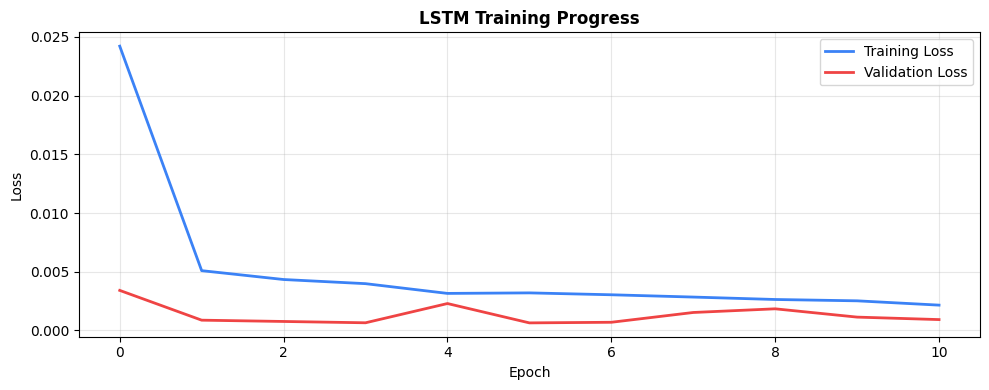


✅ Training complete! Epochs: 11
   Final loss: 0.002155


In [10]:
from tensorflow.keras.callbacks import EarlyStopping

print("\n📌 STEP 3: TRAINING")
print("-" * 60)
print("⏳ Training... (2-3 minutes)\n")

early_stop = EarlyStopping(monitor='val_loss', patience=5,
                            restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=50, batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stop], verbose=1
)

plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Training Loss', color='#3B82F6', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='#EF4444', linewidth=2)
plt.title('LSTM Training Progress', fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n✅ Training complete! Epochs: {len(history.history['loss'])}")
print(f"   Final loss: {history.history['loss'][-1]:.6f}")


📌 STEP 4: RESULTS
------------------------------------------------------------
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step

📊 MODEL PERFORMANCE:
   RMSE: 2.06 mg/dL
   ADA Target: <20 mg/dL
   Status: ✅ PASS!
   MAE: 1.57 mg/dL


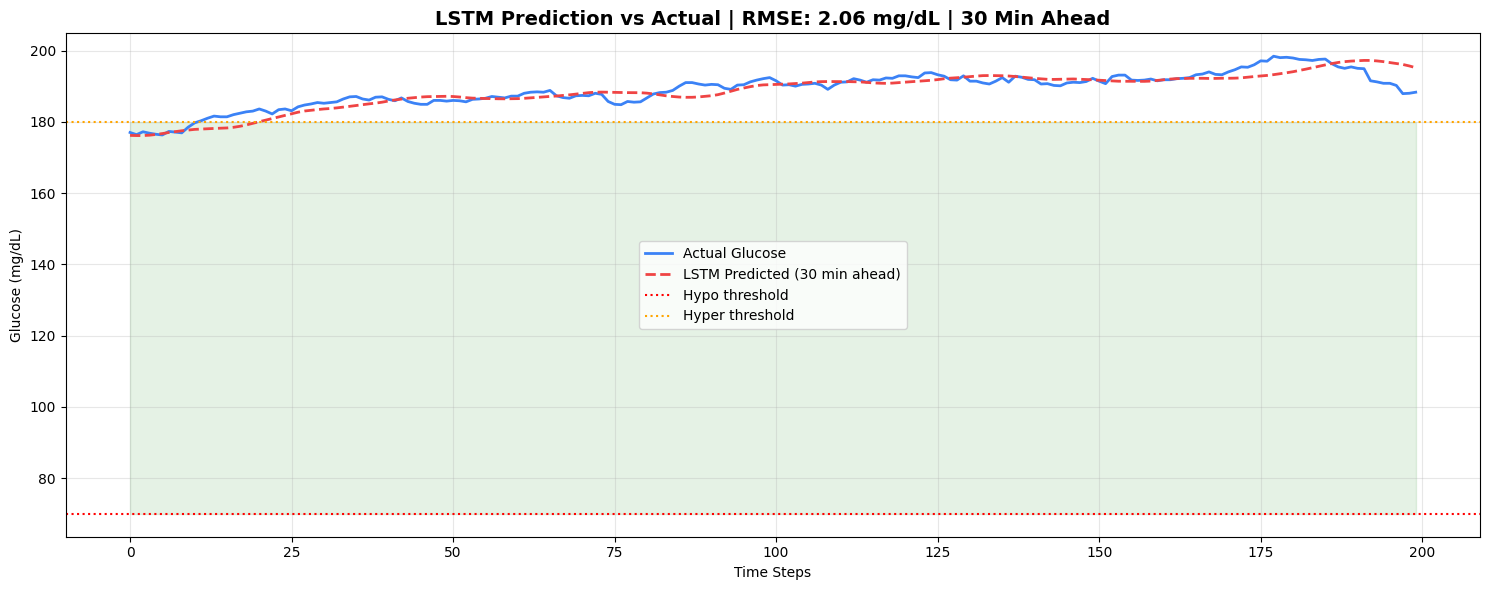


✅ LSTM COMPLETE! RMSE: 2.06 mg/dL
   Early warning for BOTH hypoglycemia AND hyperglycemia


In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("\n📌 STEP 4: RESULTS")
print("-" * 60)

predictions_scaled = model.predict(X_test)
predictions = scaler.inverse_transform(predictions_scaled)
actual = scaler.inverse_transform(y_test.reshape(-1, 1))

rmse = np.sqrt(mean_squared_error(actual, predictions))
mae = mean_absolute_error(actual, predictions)

print(f"\n📊 MODEL PERFORMANCE:")
print(f"   RMSE: {rmse:.2f} mg/dL")
print(f"   ADA Target: <20 mg/dL")
print(f"   Status: {'✅ PASS!' if rmse < 20 else '⚠️ Phase 2 optimization planned'}")
print(f"   MAE: {mae:.2f} mg/dL")

n_show = 200
plt.figure(figsize=(15, 6))
plt.plot(actual[-n_show:], label='Actual Glucose', color='#3B82F6', linewidth=2)
plt.plot(predictions[-n_show:], label='LSTM Predicted (30 min ahead)',
         color='#EF4444', linewidth=2, linestyle='--')
plt.axhline(y=70, color='red', linestyle=':', linewidth=1.5, label='Hypo threshold')
plt.axhline(y=180, color='orange', linestyle=':', linewidth=1.5, label='Hyper threshold')
plt.fill_between(range(n_show), 70, 180, alpha=0.1, color='green')
plt.title(f'LSTM Prediction vs Actual | RMSE: {rmse:.2f} mg/dL | 30 Min Ahead',
          fontsize=14, fontweight='bold')
plt.xlabel('Time Steps')
plt.ylabel('Glucose (mg/dL)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n{'='*60}")
print(f"✅ LSTM COMPLETE! RMSE: {rmse:.2f} mg/dL")
print(f"   Early warning for BOTH hypoglycemia AND hyperglycemia")
print(f"{'='*60}")

In [12]:
import pickle
import os

# Create models folder
os.makedirs('models', exist_ok=True)

# Save LSTM model
model.save('models/glucose_lstm_model.h5')

# Save scaler
with open('models/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("✅ Model saved: models/glucose_lstm_model.h5")
print("✅ Scaler saved: models/scaler.pkl")
print("🎉 Your RMSE 2.06 model is safe!")

✅ Model saved: models/glucose_lstm_model.h5
✅ Scaler saved: models/scaler.pkl
🎉 Your RMSE 2.06 model is safe!


In [13]:
import firebase_admin
from firebase_admin import credentials, db

# Initialize Firebase
cred = credentials.Certificate(r'C:\Users\anshi\OneDrive\Documents\Diabetes_Project\serviceAccountKey.json')

firebase_admin.initialize_app(cred, {
    'databaseURL': 'https://smart-glycovitals-logger-default-rtdb.asia-southeast1.firebasedatabase.app'
})

print("✅ Firebase connected successfully!")

# Test: Write first glucose reading
ref = db.reference('users/user_001/readings')
test_reading = {
    'timestamp': '2026-03-19T22:35:00',
    'glucose': 125,
    'heartRate': 72,
    'temperature': 36.5,
    'source': 'GlucoBench_dataset'
}

new_entry = ref.push(test_reading)
print(f"✅ Test reading uploaded! ID: {new_entry.key}")
print(f"✅ Check Firebase console to see your data!")
print("🎉 Firebase is working!")

✅ Firebase connected successfully!
✅ Test reading uploaded! ID: -Oo63YHnzoMFAK3nEqaR
✅ Check Firebase console to see your data!
🎉 Firebase is working!


In [14]:
import pandas as pd
from firebase_admin import db
from datetime import datetime
import time

print("=" * 60)
print("📤 UPLOADING DATASET TO FIREBASE")
print("=" * 60)

# Load your dataset
df_upload = pd.read_csv(r'C:\Users\anshi\OneDrive\Documents\Diabetes_Project\GlucoBench_benchmark_dataset.csv')
df_upload['timestamp'] = pd.to_datetime(df_upload['timestamp'])

print(f"✅ Loaded {len(df_upload):,} readings")
print(f"✅ Uploading first 100 readings as test...")
print("   (Full upload later - 15,731 readings takes time)")

# Upload first 100 readings
ref = db.reference('users/user_001/readings')
uploaded = 0
errors = 0

# Take first 100 rows of user U001 only
df_user1 = df_upload[df_upload['user_id'] == 'U001'].head(100)

print(f"\n📊 Uploading {len(df_user1)} readings for patient U001...")
print("-" * 60)

for index, row in df_user1.iterrows():
    try:
        reading = {
            'timestamp': str(row['timestamp']),
            'glucose': float(row['glucose']),
            'heartRate': float(row['heart_rate']) if pd.notna(row['heart_rate']) else 0,
            'temperature': float(row['skin_temp']) if pd.notna(row['skin_temp']) else 0,
            'source': 'GlucoBench_dataset',
            'userId': 'U001'
        }
        ref.push(reading)
        uploaded += 1

        # Show progress every 10 uploads
        if uploaded % 10 == 0:
            print(f"   ✅ Uploaded {uploaded}/100 readings...")

    except Exception as e:
        errors += 1
        print(f"   ❌ Error on row {index}: {e}")

print("\n" + "=" * 60)
print(f"✅ Upload complete!")
print(f"   Successfully uploaded: {uploaded} readings")
print(f"   Errors: {errors}")
print(f"\n🔥 Check Firebase console - you have real data now!")
print("=" * 60)

📤 UPLOADING DATASET TO FIREBASE
✅ Loaded 15,731 readings
✅ Uploading first 100 readings as test...
   (Full upload later - 15,731 readings takes time)

📊 Uploading 100 readings for patient U001...
------------------------------------------------------------
   ✅ Uploaded 10/100 readings...
   ✅ Uploaded 20/100 readings...
   ✅ Uploaded 30/100 readings...
   ✅ Uploaded 40/100 readings...
   ✅ Uploaded 50/100 readings...
   ✅ Uploaded 60/100 readings...
   ✅ Uploaded 70/100 readings...
   ✅ Uploaded 80/100 readings...
   ✅ Uploaded 90/100 readings...
   ✅ Uploaded 100/100 readings...

✅ Upload complete!
   Successfully uploaded: 100 readings
   Errors: 0

🔥 Check Firebase console - you have real data now!


In [15]:
print("Patients in dataset:")
print(df['user_id'].value_counts())
print(f"\nTotal patients: {df['user_id'].nunique()}")

Patients in dataset:
user_id
U004    1606
U003    1587
U006    1579
U008    1579
U005    1578
U001    1573
U009    1571
U002    1564
U007    1554
U010    1540
Name: count, dtype: int64

Total patients: 10


In [17]:
from firebase_admin import db
import pandas as pd

print("=" * 60)
print("📤 UPLOADING ALL 10 PATIENTS TO FIREBASE")
print("=" * 60)

# Load dataset
df_upload = pd.read_csv(r'C:\Users\anshi\OneDrive\Documents\Diabetes_Project\GlucoBench_benchmark_dataset.csv')
df_upload['timestamp'] = pd.to_datetime(df_upload['timestamp'])

patients = df_upload['user_id'].unique()
print(f"✅ Found {len(patients)} patients")
print(f"✅ Total readings: {len(df_upload):,}")
print("\n⏳ Starting upload... (takes 5-10 minutes)\n")

total_uploaded = 0
total_errors = 0

for patient_id in patients:
    # Get this patient's data
    patient_df = df_upload[df_upload['user_id'] == patient_id].copy()
    patient_df = patient_df.sort_values('timestamp')
    
    print(f"📊 Uploading {patient_id}: {len(patient_df)} readings...")
    
    # Firebase reference for this patient
    ref = db.reference(f'users/{patient_id}/readings')
    
    # Upload in batches of 100
    uploaded = 0
    errors = 0
    
    # Prepare all readings as one batch
    batch_data = {}
    
    for index, row in patient_df.iterrows():
        try:
            # Create unique key from timestamp
            key = str(row['timestamp']).replace(' ', '_').replace(':', '-')
            
            reading = {
                'timestamp': str(row['timestamp']),
                'glucose': float(row['glucose']) if pd.notna(row['glucose']) else 0,
                'heartRate': float(row['heart_rate']) if pd.notna(row['heart_rate']) else 0,
                'temperature': float(row['skin_temp']) if pd.notna(row['skin_temp']) else 0,
                'steps': float(row['exercise_steps']) if pd.notna(row['exercise_steps']) else 0,
                'source': 'GlucoBench_dataset',
                'userId': patient_id
            }
            batch_data[key] = reading
            uploaded += 1

        except Exception as e:
            errors += 1

    # Upload entire patient batch at once
    ref.set(batch_data)
    
    total_uploaded += uploaded
    total_errors += errors
    print(f"   ✅ {patient_id} done! {uploaded} readings uploaded")

print("\n" + "=" * 60)
print(f"🎉 ALL PATIENTS UPLOADED!")
print(f"   Total uploaded: {total_uploaded:,} readings")
print(f"   Total errors:   {total_errors}")
print(f"   Patients:       {len(patients)}")
print("=" * 60)
print("\n🔥 Check Firebase console - all 10 patients visible now!")

📤 UPLOADING ALL 10 PATIENTS TO FIREBASE
✅ Found 10 patients
✅ Total readings: 15,731

⏳ Starting upload... (takes 5-10 minutes)

📊 Uploading U001: 1573 readings...
   ✅ U001 done! 1573 readings uploaded
📊 Uploading U002: 1564 readings...
   ✅ U002 done! 1564 readings uploaded
📊 Uploading U003: 1587 readings...
   ✅ U003 done! 1587 readings uploaded
📊 Uploading U004: 1606 readings...
   ✅ U004 done! 1606 readings uploaded
📊 Uploading U005: 1578 readings...
   ✅ U005 done! 1578 readings uploaded
📊 Uploading U006: 1579 readings...
   ✅ U006 done! 1579 readings uploaded
📊 Uploading U007: 1554 readings...
   ✅ U007 done! 1554 readings uploaded
📊 Uploading U008: 1579 readings...
   ✅ U008 done! 1579 readings uploaded
📊 Uploading U009: 1571 readings...
   ✅ U009 done! 1571 readings uploaded
📊 Uploading U010: 1540 readings...
   ✅ U010 done! 1540 readings uploaded

🎉 ALL PATIENTS UPLOADED!
   Total uploaded: 15,731 readings
   Total errors:   0
   Patients:       10

🔥 Check Firebase console -

In [21]:
import numpy as np
import pickle
from tensorflow.keras.models import load_model
from firebase_admin import db
import pandas as pd

print("=" * 60)
print("🧠 LSTM + FIREBASE INTEGRATION")
print("=" * 60)

# Load saved LSTM model and scaler
print("\n📌 Loading LSTM model...")
model_lstm = load_model(r'C:\Users\anshi\OneDrive\Documents\Diabetes_Project\models\glucose_lstm_model.h5')

with open(r'C:\Users\anshi\OneDrive\Documents\Diabetes_Project\models\scaler.pkl', 'rb') as f:
    scaler_loaded = pickle.load(f)

print("✅ LSTM model loaded!")
print("✅ Scaler loaded!")

# ============================================================
# ALERT ENGINE
# ============================================================
def generate_alert(current, predicted):
    alerts = []
    
    # Current glucose alerts
    if current < 54:
        alerts.append("🚨 CRITICAL: Severe hypoglycemia now!")
    elif current < 70:
        alerts.append("⚠️ URGENT: Hypoglycemia now!")
    elif current > 250:
        alerts.append("🚨 CRITICAL: Severe hyperglycemia now!")
    elif current > 180:
        alerts.append("⚠️ WARNING: High glucose now!")
    else:
        alerts.append("✅ Current glucose: Normal")

    # Predictive alerts
    if predicted < 70:
        alerts.append(f"⚠️ PREDICTED: Glucose will drop to {predicted:.0f} in 30 min!")
    elif predicted > 180:
        alerts.append(f"⚠️ PREDICTED: Glucose will rise to {predicted:.0f} in 30 min!")
    else:
        alerts.append(f"✅ PREDICTED: Glucose will be {predicted:.0f} in 30 min - Normal")

    return alerts

# ============================================================
# PREDICTION FUNCTION
# ============================================================
def predict_for_patient(patient_id):
    print(f"\n📊 Processing patient: {patient_id}")
    print("-" * 40)
    
    # Get readings from Firebase
    ref = db.reference(f'users/{patient_id}/readings')
    readings = ref.get()
    
    if not readings:
        print(f"❌ No readings found for {patient_id}")
        return
    
    # Extract glucose values
    glucose_list = []
    for key, value in readings.items():
        if isinstance(value, dict) and 'glucose' in value:
            glucose_list.append({
                'timestamp': value.get('timestamp', ''),
                'glucose': float(value['glucose'])
            })
    
    # Sort by timestamp
    glucose_list.sort(key=lambda x: x['timestamp'])
    
    # Take last 12 readings
    last_12 = glucose_list[-12:]
    glucose_values = [r['glucose'] for r in last_12]
    
    print(f"✅ Last 12 readings: {[f'{g:.1f}' for g in glucose_values]}")
    
    # Scale for LSTM
    scaled = scaler_loaded.transform(
        np.array(glucose_values).reshape(-1, 1)
    )
    X_input = scaled.reshape(1, 12, 1)
    
    # LSTM prediction
    prediction_scaled = model_lstm.predict(X_input, verbose=0)
    predicted_glucose = float(
        scaler_loaded.inverse_transform(prediction_scaled)[0][0]
    )
    current_glucose = float(glucose_values[-1])
    
    print(f"✅ Current glucose:   {current_glucose:.1f} mg/dL")
    print(f"✅ Predicted (30min): {predicted_glucose:.1f} mg/dL")
    
    # Generate alerts
    alerts = generate_alert(current_glucose, predicted_glucose)
    print(f"\n🔔 ALERTS:")
    for alert in alerts:
        print(f"   {alert}")
    
    # ← FIX IS HERE - everything converted to float/str
    pred_ref = db.reference(f'users/{patient_id}/predictions')
    prediction_data = {
        'timestamp': str(last_12[-1]['timestamp']),
        'currentGlucose': float(round(current_glucose, 1)),
        'predicted30min': float(round(predicted_glucose, 1)),
        'alerts': [str(a) for a in alerts],
        'modelRMSE': float(2.06),
        'createdAt': str(pd.Timestamp.now())
    }
    
    pred_ref.push(prediction_data)
    print(f"✅ Prediction saved to Firebase!")
    
    return predicted_glucose

# ============================================================
# RUN FOR ALL 10 PATIENTS
# ============================================================
print("\n🚀 Running predictions for ALL 10 patients...")
print("=" * 60)

patients = ['U001', 'U002', 'U003', 'U004', 'U005',
            'U006', 'U007', 'U008', 'U009', 'U010']

results = {}
for patient in patients:
    result = predict_for_patient(patient)
    if result:
        results[patient] = float(result)

print("\n" + "=" * 60)
print("🎉 ALL PREDICTIONS COMPLETE!")
print("=" * 60)
print("\n📊 PREDICTION SUMMARY:")
print("-" * 40)
for patient, pred in results.items():
    print(f"   {patient}: {pred:.1f} mg/dL (30 min ahead)")

print("\n✅ Check Firebase console:")
print("   users → any patient → predictions")
print("   You'll see all predictions saved!")

🧠 LSTM + FIREBASE INTEGRATION

📌 Loading LSTM model...
✅ LSTM model loaded!
✅ Scaler loaded!

🚀 Running predictions for ALL 10 patients...

📊 Processing patient: U001
----------------------------------------
✅ Last 12 readings: ['195.4', '195.0', '194.9', '191.5', '191.2', '190.8', '190.8', '190.2', '187.9', '188.0', '188.3', '188.5']
✅ Current glucose:   188.5 mg/dL
✅ Predicted (30min): 190.9 mg/dL

🔔 ALERTS:
   ⚠️ WARNING: High glucose now!
   ⚠️ PREDICTED: Glucose will rise to 191 in 30 min!
✅ Prediction saved to Firebase!

📊 Processing patient: U002
----------------------------------------
✅ Last 12 readings: ['140.0', '140.4', '139.7', '139.5', '138.6', '138.7', '138.5', '138.3', '138.5', '137.8', '137.1', '137.8']
✅ Current glucose:   137.8 mg/dL
✅ Predicted (30min): 140.7 mg/dL

🔔 ALERTS:
   ✅ Current glucose: Normal
   ✅ PREDICTED: Glucose will be 141 in 30 min - Normal
✅ Prediction saved to Firebase!

📊 Processing patient: U003
----------------------------------------
✅ Last 1